# Evaluate models

In [1]:
import anndata as ad
import os
from data_processing import preprocess
from sklearn.metrics import confusion_matrix, f1_score, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
from src.trainer import CellCLassificationTrainer
from src.transformer_classifier import TransformerClassifier
from src.dataset import CustomDataset
from pytorch_lightning import Trainer
from torch.utils.data import DataLoader
import torch.nn as nn
import torch

In [2]:
data_dir = "data"
models_dir = "models"
data_pth = os.path.join(data_dir, 'cell_w_split.h5ad')

In [3]:
adata = ad.read_h5ad(data_pth)

### Logistic regression

### Load model

In [4]:
#classifier = LogisticRegression()
model_path = os.path.join(models_dir, 'log_reg_classifier_with_stats.pkl')

with open(model_path, 'rb') as f:
    model_data = pickle.load(f)
    classifier = model_data["classifier"]
    mean_per_gene = model_data["mean_train"]
    std_per_gene = model_data["std_train"]
    genes_to_keep = model_data["genes_to_keep"]

### Pre-process data

In [5]:
args_normalization = {
    "log_transform": True, 
    "normalize_per_cell": True, 
    "normalize_per_gene": False, 
    "filter_top_genes": True,
    "filter_min_counts": True,
    "min_counts": 3, 
    "n_top_genes": 1000
}

test_set = adata[adata.obs["split"] == "test"]
preprocess(test_set, is_train_set=False, genes_to_keep=genes_to_keep, mean_train=mean_per_gene, std_train=std_per_gene, **args_normalization)
X_test, y_test = test_set.X, test_set.obs["encoded_class"]

### Get prediction and metrics

In [25]:
y_test_hat = classifier.predict(X_test)
accuracy = accuracy_score(y_test, y_test_hat)
f1_macro = f1_score(y_test, y_test_hat, average="macro")
f1_micro = f1_score(y_test, y_test_hat, average="micro")
f1_weighted = f1_score(y_test, y_test_hat, average="weighted")
cm = confusion_matrix(y_test, y_test_hat)

print(f"Accuracy: {accuracy:.4f}")
print(f"F1 score (macro): {f1_macro:.4f}")
print(f"F1 score (weighted): {f1_weighted:.4f}")

Accuracy: 0.8026
F1 score (macro): 0.6674
F1 score (weighted): 0.7954


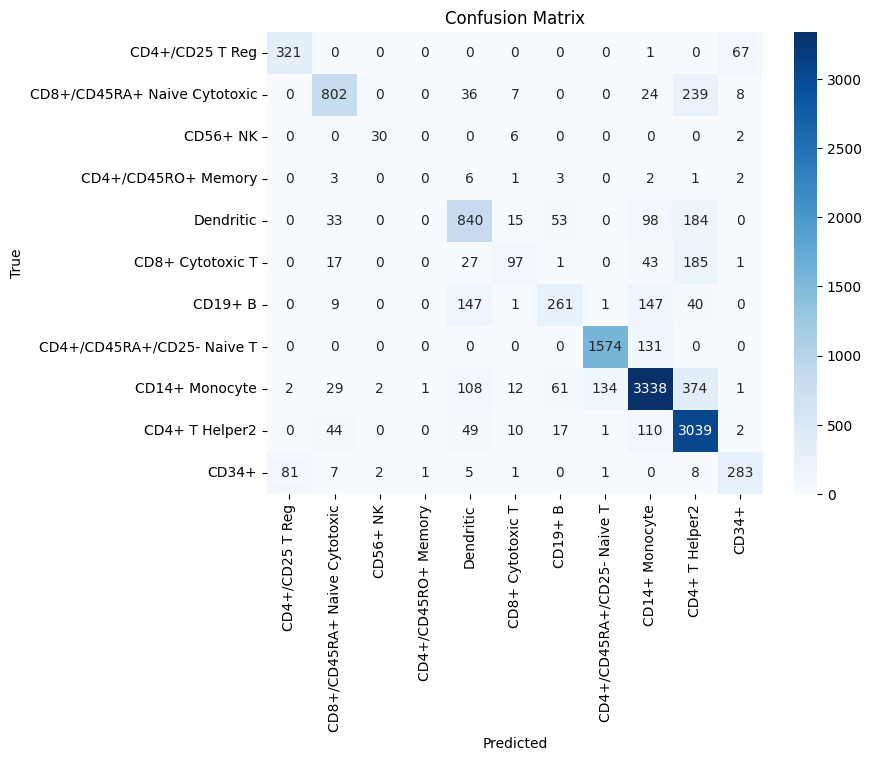

In [8]:
# Get unique values from both columns
encoded_classes = test_set.obs["encoded_class"].unique()
classes = test_set.obs["class"].unique()

# Create a correspondence dictionary
class_correspondence = {encoded_class: class_name for encoded_class, class_name in zip(encoded_classes, classes)}
cell_classes = list(class_correspondence.values())


# Create a heatmap to display the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=cell_classes, yticklabels=cell_classes)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

# Attention-based

### Load model

In [16]:
args_normalization = {
    "log_transform": True, 
    "normalize_per_cell": False, 
    "normalize_per_gene": False, 
    "filter_top_genes": True,
    "filter_min_counts": False,
    "min_counts": 3, 
    "n_top_genes": 1000
}   

num_expression_levels = 50
embed_dim = 200
num_transformer_layers = 1
num_transformer_heads = 8
use_custom_attention = True

In [17]:
test_dataset = CustomDataset(
    data_pth, 
    "test", 
    args_normalization,
    genes_to_keep=genes_to_keep, 
    mean_per_gene=mean_per_gene, 
    std_per_gene=std_per_gene,
    max_value=6,
    num_bins=num_expression_levels,
    keep_ratio=1.0,
    use_precomputed_stats_and_features=True
    )

test_dataloader = DataLoader(test_dataset, batch_size=128, shuffle=False, num_workers=4)

In [18]:
model = TransformerClassifier(
    num_expression_levels=num_expression_levels,
    embed_dim=embed_dim, 
    num_classes=test_dataset.num_classes, 
    num_layers=num_transformer_layers, 
    fc_hidden_dim=4*embed_dim, 
    num_heads=num_transformer_heads,
    use_custom_attention=True
    )

print(model)

TransformerClassifier(
  (exp_embedding): Embedding(50, 200)
  (pos_encoder): PositionalEncoding()
  (layers): ModuleList(
    (0): TransformerLayer(
      (attn): CustomMultiheadAttention(
        (q_proj): Linear(in_features=200, out_features=200, bias=False)
        (k_proj): Linear(in_features=200, out_features=200, bias=False)
        (v_proj): Linear(in_features=200, out_features=200, bias=False)
        (softmax): Softmax(dim=-1)
        (out_linear): Linear(in_features=200, out_features=200, bias=True)
      )
      (linear1): Linear(in_features=200, out_features=800, bias=True)
      (linear2): Linear(in_features=800, out_features=200, bias=True)
      (norm1): LayerNorm((200,), eps=1e-05, elementwise_affine=True)
      (norm2): LayerNorm((200,), eps=1e-05, elementwise_affine=True)
      (relu): ReLU()
      (dropout): Dropout(p=0.0, inplace=False)
    )
  )
  (linear): Linear(in_features=200, out_features=11, bias=True)
)


In [19]:
model_path = os.path.join(models_dir, 'best_model_embed_dim_200_num_layers_1_base_lr_0.001_num_expression_levels_50_bs_256_valid_init-v5.ckpt')

ckpt = torch.load(model_path, map_location="cpu")

trainer_module = CellCLassificationTrainer(
    model=model,
    criterion=nn.CrossEntropyLoss(),
)
trainer_module.load_state_dict(ckpt['state_dict'], strict=True)
trainer = Trainer()

/home/quintana/github/cell-classifier/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:734: UserWarning: Can't initialize NVML
  warnings.warn("Can't initialize NVML")
GPU available: False, used: False
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs


In [20]:
ckpt['epoch']

14

In [21]:
test_result = trainer.test(model=trainer_module, dataloaders=test_dataloader)

Testing DataLoader 0: 100%|██████████| 104/104 [03:52<00:00,  0.45it/s]


┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│         test_acc          │    0.6679809093475342     │
│       test_f1_macro       │     0.574255645275116     │
│     test_f1_weighted      │    0.6815537214279175     │
│         test_loss         │    0.9511792063713074     │
└───────────────────────────┴───────────────────────────┘

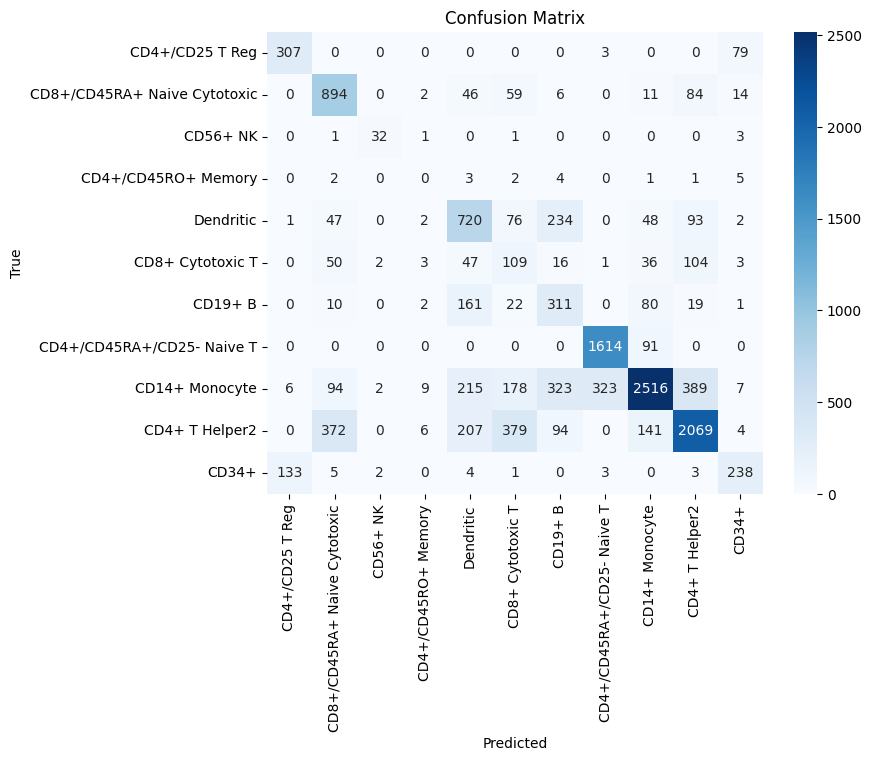

In [22]:
# Get unique values from both columns
encoded_classes = test_set.obs["encoded_class"].unique()
classes = test_set.obs["class"].unique()

# Create a correspondence dictionary
class_correspondence = {encoded_class: class_name for encoded_class, class_name in zip(encoded_classes, classes)}
cell_classes = list(class_correspondence.values())


# Create a heatmap to display the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(trainer_module.test_cm, annot=True, fmt='d', cmap='Blues', xticklabels=cell_classes, yticklabels=cell_classes)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()